Visualisations

This notebook creates every figure used in the report.=

| Figure | Report section | What it shows |
|---|---|---|
| 1 | Problem & Data | Distribution of the number of ratings and the popularity threshold |
| 2 | Methods (EDA) | Missing values and how they relate to popularity |
| 3 | Methods (EDA) | Numerical features for popular vs less popular books |
| 4 | Results | CatBoost compared with the baseline model |
| 5 | Results | Confusion matrix and ROC curve |



In [ ]:
%pip install -q catboost

In [ ]:
# Data processing
import os
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Modelling and evaluation
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)
from catboost import CatBoostClassifier

# Run from the repo's Notebook folder the data is at ../Data.
# On Google Colab, upload "Goodreads Books EDA.csv" when asked.
DATA_PATH = "/content/Goodreads Books EDA.csv"
if not os.path.exists(DATA_PATH):
    from google.colab import files
    print("Please upload 'Goodreads Books EDA.csv'")
    DATA_PATH = list(files.upload().keys())[0]

# Folder for the exported figures
FIG_DIR = "../Figures" if os.path.isdir("../Data") else "Figures"
os.makedirs(FIG_DIR, exist_ok=True)

# One colour per class, used in every figure (colour-blind safe)
POPULAR = "#E07A1F"
LESS_POPULAR = "#3D5A80"
NEUTRAL = "#9AA5B1"

# Sizes for a two-column report: one column is about 3.4 inches wide
ONE_COL = 3.4
TWO_COL = 7.0

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 9.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linewidth": 0.6,
    "figure.dpi": 110,
})

def save(fig, name):
    """Save a figure as PNG and PDF in the Figures folder."""
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{FIG_DIR}/{name}.pdf", bbox_inches="tight")
    plt.show()

In [ ]:
# Load the data
df = pd.read_csv(DATA_PATH)

# Keep an untouched copy of the page counts for the missing-value figure
df["pages_missing"] = df["num_pages"] <= 0

# Same cleaning as the training notebook
df.loc[df["num_pages"] <= 0, "num_pages"] = np.nan
df["title_length"] = df["title"].astype(str).str.split().str.len()
df["description_length"] = df["description"].astype(str).str.split().str.len()

categorical_features = ["main_author", "primary_genre", "language"]
for column in categorical_features:
    df[column] = df[column].astype(str).str.strip()

df.loc[df["primary_genre"].str.contains("Goodreads", case=False, na=False),
       "primary_genre"] = "Unknown"

# Target: popular if the book has at least 10,000 ratings
POPULARITY_THRESHOLD = 10000
df["popularity"] = (df["num_ratings"] >= POPULARITY_THRESHOLD).astype(int)

features = ["main_author", "primary_genre", "language",
            "num_pages", "title_length", "description_length"]
X = df[features].copy()
y = df["popularity"]

print("Dataset shape:", df.shape)
print(f"Popular books: {y.sum()} ({y.mean() * 100:.1f}%)")

Dataset shape: (19941, 23)
Popular books: 5034 (25.2%)


In [ ]:
#Recreate the train-test split and the CatBoost model

groups = (df["title"].astype(str).str.lower().str.strip()
          + "|" + df["main_author"].str.lower().str.strip())

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# None matches ML_Model_Training_Updated.ipynb (the tuned model).
# Set to "Balanced" to match the original ML_Model_Training.ipynb.
CLASS_WEIGHTS = None

model = CatBoostClassifier(iterations=300, learning_rate=0.05, depth=6,
                           auto_class_weights=CLASS_WEIGHTS, random_seed=42,
                           verbose=0, allow_writing_files=False)
model.fit(X_train, y_train, cat_features=categorical_features)

y_pred = model.predict(X_test).ravel().astype(int)
y_prob = model.predict_proba(X_test)[:, 1]

print(f"CatBoost test accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"CatBoost ROC AUC: {roc_auc_score(y_test, y_prob):.4f}")

CatBoost test accuracy: 88.23%
CatBoost ROC AUC: 0.9262


In [ ]:
#Compare with the baseline model

baseline_pred = np.zeros(len(y_test), dtype=int)
baseline_prob = np.zeros(len(y_test))

def metrics(y_true, pred, prob):
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC AUC": roc_auc_score(y_true, prob),
    }

results = pd.DataFrame({
    "Baseline (majority class)": metrics(y_test, baseline_pred, baseline_prob),
    "CatBoost": metrics(y_test, y_pred, y_prob),
}).T

# Saved so the same numbers can be used in the report's results table
results.round(4).to_csv(f"{FIG_DIR}/model_comparison.csv")
results.round(3)

,Accuracy,Precision,Recall,F1,ROC AUC
Baseline (majority class),0.747,0.000,0.000,0.000,0.500
CatBoost,0.882,0.792,0.725,0.757,0.926


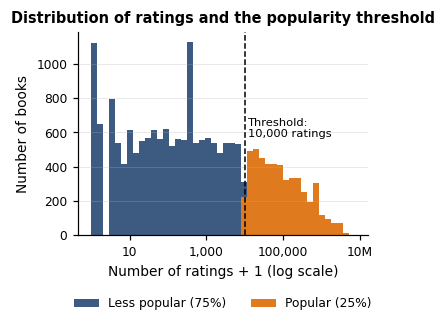

In [ ]:
# Figure 1: How the popularity label is defined

fig, ax = plt.subplots(figsize=(ONE_COL, 2.4))

ratings_plus_one = df["num_ratings"] + 1
bins = np.logspace(0, np.log10(ratings_plus_one.max()), 45)

ax.hist(ratings_plus_one[df["popularity"] == 0], bins=bins, color=LESS_POPULAR,
        label=f"Less popular ({(y == 0).mean() * 100:.0f}%)")
ax.hist(ratings_plus_one[df["popularity"] == 1], bins=bins, color=POPULAR,
        label=f"Popular ({(y == 1).mean() * 100:.0f}%)")
ax.axvline(POPULARITY_THRESHOLD, color="black", linestyle="--", linewidth=1)
ax.text(POPULARITY_THRESHOLD * 1.25, ax.get_ylim()[1] * 0.58, "Threshold:\n10,000 ratings",
        fontsize=7.5, va="top")

ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda v, _: f"{v:,.0f}" if v < 1e6 else f"{v / 1e6:.0f}M"))
ax.set_xlabel("Number of ratings + 1 (log scale)")
ax.set_ylabel("Number of books")
ax.set_title("Distribution of ratings and the popularity threshold")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
ax.grid(axis="x", visible=False)

save(fig, "fig1_target_definition")

,Feature,Missing (%),Popular when missing (%),Popular when known (%)
0,Genre,25.4,0.2,33.8
1,Description,13.4,5.6,28.3
2,Language,13.9,11.8,27.4
3,Page count,3.2,32.0,25.0


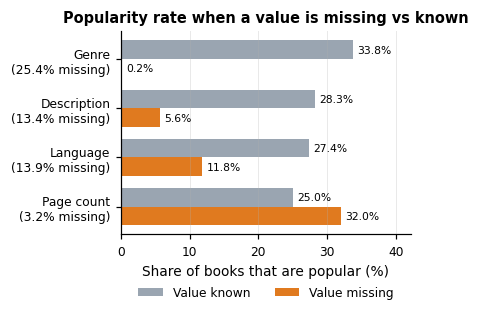

In [ ]:
#Figure 2: Missing values and popularity

missing_flags = {
    "Genre": df["primary_genre"] == "Unknown",
    "Description": df["description"].astype(str).str.strip() == "Unknown",
    "Language": df["language"] == "Unknown",
    "Page count": df["pages_missing"],
}

rows = []
for name, missing in missing_flags.items():
    rows.append({
        "Feature": name,
        "Missing (%)": missing.mean() * 100,
        "Popular when missing (%)": df.loc[missing, "popularity"].mean() * 100,
        "Popular when known (%)": df.loc[~missing, "popularity"].mean() * 100,
    })
missing_table = pd.DataFrame(rows)
display(missing_table.round(1))

fig, ax = plt.subplots(figsize=(ONE_COL, 2.4))
pos = np.arange(len(missing_table))
height = 0.38

ax.barh(pos - height / 2, missing_table["Popular when known (%)"], height,
        color=NEUTRAL, label="Value known")
ax.barh(pos + height / 2, missing_table["Popular when missing (%)"], height,
        color=POPULAR, label="Value missing")

for i, row in missing_table.iterrows():
    ax.text(row["Popular when known (%)"] + 0.6, i - height / 2,
            f"{row['Popular when known (%)']:.1f}%", va="center", fontsize=7)
    ax.text(row["Popular when missing (%)"] + 0.6, i + height / 2,
            f"{row['Popular when missing (%)']:.1f}%", va="center", fontsize=7)

ax.set_yticks(pos)
ax.set_yticklabels([f"{f}\n({m:.1f}% missing)" for f, m in
                    zip(missing_table["Feature"], missing_table["Missing (%)"])])
ax.invert_yaxis()
ax.set_xlabel("Share of books that are popular (%)")
ax.set_title("Popularity rate when a value is missing vs known")
ax.set_xlim(0, missing_table[["Popular when known (%)",
                              "Popular when missing (%)"]].values.max() * 1.25)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
ax.grid(axis="y", visible=False)

save(fig, "fig2_missing_vs_popularity")

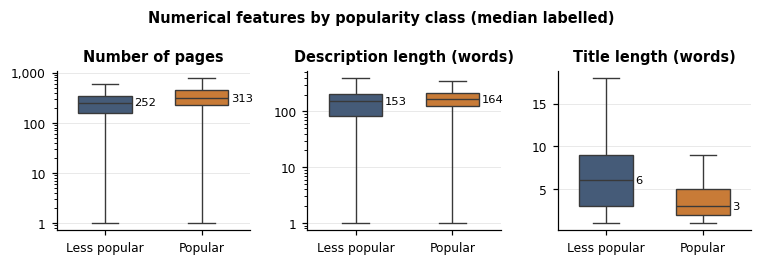

In [ ]:
# Figure 3: Numerical features for popular and less popular books

plot_df = df.assign(Class=df["popularity"].map({0: "Less popular", 1: "Popular"}))

# A missing description or title is stored as "Unknown", which would count as 1 word,
# so those books are left out of the matching panel
plot_df.loc[plot_df["description"].astype(str).str.strip() == "Unknown", "description_length"] = np.nan
plot_df.loc[plot_df["title"].astype(str).str.strip() == "Unknown", "title_length"] = np.nan
palette = {"Less popular": LESS_POPULAR, "Popular": POPULAR}
order = ["Less popular", "Popular"]

panels = [
    ("num_pages", "Number of pages", True),
    ("description_length", "Description length (words)", True),
    ("title_length", "Title length (words)", False),
]

fig, axes = plt.subplots(1, 3, figsize=(TWO_COL, 2.4))
for ax, (column, label, use_log) in zip(axes, panels):
    data = plot_df[plot_df[column] > 0]
    sns.boxplot(data=data, x="Class", y=column, hue="Class", order=order,
                palette=palette, showfliers=False, width=0.55, linewidth=0.9,
                legend=False, ax=ax)
    if use_log:
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    medians = data.groupby("Class")[column].median()
    for i, cls in enumerate(order):
        ax.text(i + 0.3, medians[cls], f"{medians[cls]:,.0f}", fontsize=7.5,
                va="center", ha="left", color="black")
    ax.set_title(label)
    ax.set_xlabel("")
    ax.set_ylabel("")

fig.suptitle("Numerical features by popularity class (median labelled)",
             fontsize=9.5, fontweight="bold", y=0.98)
fig.tight_layout()

save(fig, "fig3_numeric_features_by_class")

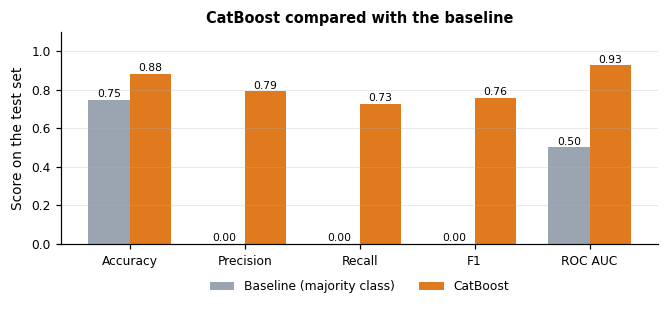

In [ ]:
# Figure 4: CatBoost compared with the baseline

metric_order = ["Accuracy", "Precision", "Recall", "F1", "ROC AUC"]
model_colours = {"Baseline (majority class)": NEUTRAL,
                 "CatBoost": POPULAR}

fig, ax = plt.subplots(figsize=(TWO_COL, 2.5))
pos = np.arange(len(metric_order))
width = 0.36

for i, (name, colour) in enumerate(model_colours.items()):
    values = results.loc[name, metric_order].values
    bars = ax.bar(pos + (i - 0.5) * width, values, width, color=colour, label=name)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.015, f"{value:.2f}",
                ha="center", fontsize=7)

ax.set_xticks(pos)
ax.set_xticklabels(metric_order)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score on the test set")
ax.set_title("CatBoost compared with the baseline")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.grid(axis="x", visible=False)

save(fig, "fig4_model_vs_baseline")

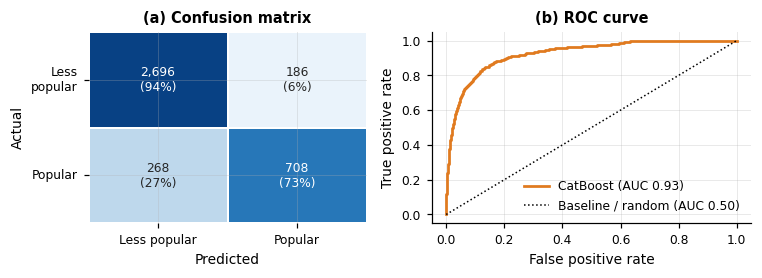

In [ ]:
# Figure 5: Confusion matrix and ROC curve (CatBoost, test set)
fig, axes = plt.subplots(1, 2, figsize=(TWO_COL, 2.6), gridspec_kw={"width_ratios": [1, 1.15]})

# (a) Confusion matrix with counts and row percentages
cm = confusion_matrix(y_test, y_pred)
row_pct = cm / cm.sum(axis=1, keepdims=True) * 100
labels = np.array([[f"{cm[r, c]:,}\n({row_pct[r, c]:.0f}%)" for c in range(2)]
                   for r in range(2)])
sns.heatmap(row_pct, annot=labels, fmt="", cmap="Blues", cbar=False, vmin=0, vmax=100,
            linewidths=1, linecolor="white", annot_kws={"fontsize": 8}, ax=axes[0])
axes[0].set_xticklabels(["Less popular", "Popular"])
axes[0].set_yticklabels(["Less\npopular", "Popular"], rotation=0)
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].set_title("(a) Confusion matrix")

# (b) ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color=POPULAR, linewidth=1.8,
             label=f"CatBoost (AUC {roc_auc_score(y_test, y_prob):.2f})")
axes[1].plot([0, 1], [0, 1], color="black", linestyle=":", linewidth=1,
             label="Baseline / random (AUC 0.50)")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("(b) ROC curve")
axes[1].legend(frameon=False, loc="lower right")

fig.tight_layout()
save(fig, "fig5_confusion_matrix_roc")